In [2]:
!pip install pandas numpy scikit-learn matplotlib seaborn torch


In [3]:
from google.colab import files
uploaded = files.upload()

Saving maharashtra_vulnerability.csv to maharashtra_vulnerability.csv


In [4]:
import pandas as pd
import numpy as np

df = pd.read_csv("maharashtra_vulnerability.csv")

print("Dataset loaded successfully!")
print(df.head())
print("Dataset shape:", df.shape)

Dataset loaded successfully!
      District                 Zone  Latitude  Longitude  Max Temp (°C)  \
0  Ahilyanagar  Western Maharashtra    19.095     74.749           32.0   
1        Akola             Vidarbha    20.709     77.002           34.9   
2       Alibag               Konkan    18.641     72.872           32.0   
3     Amravati             Vidarbha    20.933     77.752           32.0   
4         Beed           Marathwada    18.989     75.756           32.0   

   Min Temp (°C)  Rainfall (mm)  Density  Urban (%)  Forest Area (sq km)  
0           18.5          358.8      266       20.1            1848.1900  
1           22.6          414.0      321       25.0             413.7400  
2           19.8          626.7      325       30.7            1666.8092  
3           19.8          626.7      325       30.7            1666.8092  
4           19.8          626.7      325       30.7            1666.8092  
Dataset shape: (34, 10)


In [5]:
features = [
    "Max Temp (°C)",
    "Min Temp (°C)",
    "Rainfall (mm)",
    "Density",
    "Urban (%)",
    "Forest Area (sq km)"
]

for col in features:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.dropna(subset=features).reset_index(drop=True)

max_temp = df["Max Temp (°C)"]
min_temp = df["Min Temp (°C)"]
rainfall = df["Rainfall (mm)"]
density = df["Density"]
urban = df["Urban (%)"]
forest = df["Forest Area (sq km)"]

aridity = max_temp / np.maximum(rainfall, 1) * 1000

print("Seven features prepared!")

Seven features prepared!


In [6]:
def normalize(x):
    return (x - x.min()) / (x.max() - x.min() + 1e-8)

df["HVI"] = (
    0.25 * normalize(max_temp) +
    0.10 * normalize(min_temp) +
    0.20 * (1 - normalize(rainfall)) +
    0.15 * normalize(density) +
    0.10 * normalize(urban) +
    0.10 * (1 - normalize(forest)) +
    0.10 * normalize(aridity)
) * 100

print(df[["District", "HVI"]].head())

      District        HVI
0  Ahilyanagar  58.364371
1        Akola  74.350547
2       Alibag  56.586309
3     Amravati  56.586309
4         Beed  56.586309


In [7]:
import torch
from torch import nn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = df[features].copy()
X["Aridity_Proxy"] = aridity

y = df["HVI"].values.reshape(-1, 1)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=27
)

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

X_train = torch.tensor(X_train, dtype=torch.float32)
X_test = torch.tensor(X_test, dtype=torch.float32)

y_train = torch.tensor(y_train, dtype=torch.float32)
y_test = torch.tensor(y_test, dtype=torch.float32)

class HeatModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(7, 32),
            nn.ReLU(),
            nn.Linear(32, 16),
            nn.ReLU(),
            nn.Linear(16, 1),
            nn.Sigmoid()
        )

    def forward(self, x):
        return self.network(x) * 100

model = HeatModel()

criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.006)

for epoch in range(900):
    optimizer.zero_grad()
    output = model(X_train)
    loss = criterion(output, y_train)
    loss.backward()
    optimizer.step()

print("HeatShield MH model trained successfully!")

HeatShield MH model trained successfully!


In [8]:
model.eval()

with torch.no_grad():
    predictions = model(X_test)
    mse = criterion(predictions, y_test)

print("Mean Squared Error:", mse.item())

Mean Squared Error: 47.14415740966797


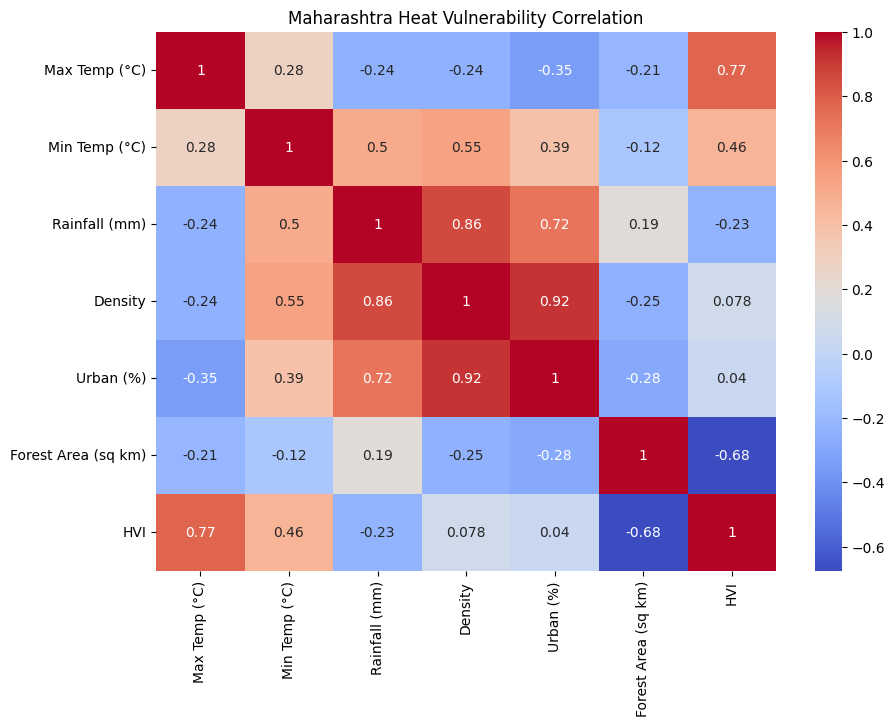

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 7))

sns.heatmap(
    df[features + ["HVI"]].corr(),
    annot=True,
    cmap="coolwarm"
)

plt.title("Maharashtra Heat Vulnerability Correlation")
plt.show()

In [10]:
torch.save(model.state_dict(), "heatshield_model.pth")

from google.colab import files
files.download("heatshield_model.pth")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [11]:
model.eval()

all_scaled = scaler.transform(X)

all_tensor = torch.tensor(
    all_scaled, dtype=torch.float32
)

with torch.no_grad():
    df["Predicted_HVI"] = model(all_tensor).numpy().flatten()

print("Maharashtra HVI Predictions:")
display(df[["District", "Predicted_HVI"]])

Maharashtra HVI Predictions:


,District,Predicted_HVI
0,Ahilyanagar,58.364372
1,Akola,74.350548
2,Alibag,56.586311
3,Amravati,56.586311
4,Beed,56.586311
5,Bhandara,56.586311
6,Buldhana,56.586311
7,Chandrapur,56.586311
8,Chhatrapati Sambhajinagar,59.703888
9,Dharashiv,56.586311


In [12]:
def category(score):
    if score < 25:
        return "Low"
    elif score < 45:
        return "Moderate"
    elif score < 65:
        return "High"
    else:
        return "Very High"

df["Vulnerability"] = df["Predicted_HVI"].apply(category)

display(df[["District", "Predicted_HVI", "Vulnerability"]])

,District,Predicted_HVI,Vulnerability
0,Ahilyanagar,58.364372,High
1,Akola,74.350548,Very High
2,Alibag,56.586311,High
3,Amravati,56.586311,High
4,Beed,56.586311,High
5,Bhandara,56.586311,High
6,Buldhana,56.586311,High
7,Chandrapur,56.586311,High
8,Chhatrapati Sambhajinagar,59.703888,High
9,Dharashiv,56.586311,High


In [13]:
df.to_csv("Maharashtra_HVI_Predictions.csv", index=False)

from google.colab import files
files.download("Maharashtra_HVI_Predictions.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [14]:
torch.save({
    "model_state_dict": model.state_dict(),
    "scaler_mean": scaler.mean_,
    "scaler_scale": scaler.scale_,
    "features": features + ["Aridity_Proxy"]
}, "HeatShield_MH_Complete.pth")

files.download("HeatShield_MH_Complete.pth")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>